In [1]:
from google.colab import files
uploaded = files.upload()

Saving Luxury_product.xlsx to Luxury_product.xlsx


In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_excel("Luxury_product.xlsx")
df.head()

,Product_ID,Parent Company,Brands,Official Website,Place of Origin,Headquarters,Production,Year Founded,Founded Age,Founder,Luxury Tier,Signature Product,Sustainability Initiatives,Target Gender,Target Customer,Average Price Range,Highest Price Range,Number of Stores,Products Offered,Countries Available
0,LV0001,LVMH,Barton Perreira,bartonperreira.com,"Los Angeles, California, USA","Los Angeles, california, USA",Fashion & Leather Goods,2007,19,Bill Barton & Patty Perreira,Premium Luxury,Joe Sunglasses,"Handmade Japanese Acetate eyewear, Responsible...",Male & Female,"Affluent eyewear buyers, luxury fashion consumers","$2,000–$5,000","$1,000,000+",460,4500,65
1,LV0002,LVMH,Berluti,berluti.com,"Paris, France","Paris, France",Fashion & Leather Goods,1895,131,Alessandro Berluti,Haute Luxury,Alessandro Oxford Shoes,"Leather Working Group-certified leather, Respo...",Male,"HNWI, executives, luxury menswear customers","$2,500–$6,000","$500,000+",290,3500,55
2,LV0003,LVMH,Celine,celine.com,"Paris, France","Paris, France",Fashion & Leather Goods,1945,81,Celine Vipiana,High Luxury,Triomphe Bag,"LVMH LIFE 360, Responsible leather sourcing",Female,"HNWI, luxury fashion wnthusiasts","$2,000–$5,500","$350,000+",270,2500,50
3,LV0004,LVMH,Christian Dior Couture,dior.com,"Paris, France","Paris, France",Fashion & Leather Goods,1946,80,Christian Dior,Ultra Luxury,Lady Dior Bag,"LIFE 360, Sustainable materials, eco-designed ...",Male & Female,"HNWI,luxury fashion customers","$1,800–$4,500","$120,000+",180,2000,45
4,LV0005,LVMH,Fendi,fendi.com,"Rome, Italy","Rome, Italy",Fashion & Leather Goods,1925,101,Adele Casagrande Fendi & Edoardo Fendi,Ultra Luxury,Baguette Bag,"Certificate fur and leather sourcing, Circular...",Male & Female,Affluent luxury consumers,"$2,000–$4,500","$100,000+",200,2200,40


In [4]:
df.shape[0]
df.shape[1]
df.head()

,Product_ID,Parent Company,Brands,Official Website,Place of Origin,Headquarters,Production,Year Founded,Founded Age,Founder,Luxury Tier,Signature Product,Sustainability Initiatives,Target Gender,Target Customer,Average Price Range,Highest Price Range,Number of Stores,Products Offered,Countries Available
0,LV0001,LVMH,Barton Perreira,bartonperreira.com,"Los Angeles, California, USA","Los Angeles, california, USA",Fashion & Leather Goods,2007,19,Bill Barton & Patty Perreira,Premium Luxury,Joe Sunglasses,"Handmade Japanese Acetate eyewear, Responsible...",Male & Female,"Affluent eyewear buyers, luxury fashion consumers","$2,000–$5,000","$1,000,000+",460,4500,65
1,LV0002,LVMH,Berluti,berluti.com,"Paris, France","Paris, France",Fashion & Leather Goods,1895,131,Alessandro Berluti,Haute Luxury,Alessandro Oxford Shoes,"Leather Working Group-certified leather, Respo...",Male,"HNWI, executives, luxury menswear customers","$2,500–$6,000","$500,000+",290,3500,55
2,LV0003,LVMH,Celine,celine.com,"Paris, France","Paris, France",Fashion & Leather Goods,1945,81,Celine Vipiana,High Luxury,Triomphe Bag,"LVMH LIFE 360, Responsible leather sourcing",Female,"HNWI, luxury fashion wnthusiasts","$2,000–$5,500","$350,000+",270,2500,50
3,LV0004,LVMH,Christian Dior Couture,dior.com,"Paris, France","Paris, France",Fashion & Leather Goods,1946,80,Christian Dior,Ultra Luxury,Lady Dior Bag,"LIFE 360, Sustainable materials, eco-designed ...",Male & Female,"HNWI,luxury fashion customers","$1,800–$4,500","$120,000+",180,2000,45
4,LV0005,LVMH,Fendi,fendi.com,"Rome, Italy","Rome, Italy",Fashion & Leather Goods,1925,101,Adele Casagrande Fendi & Edoardo Fendi,Ultra Luxury,Baguette Bag,"Certificate fur and leather sourcing, Circular...",Male & Female,Affluent luxury consumers,"$2,000–$4,500","$100,000+",200,2200,40


In [5]:
df.columns=df.columns.str.strip()
print(df.columns.tolist())

['Product_ID', 'Parent Company', 'Brands', 'Official Website', 'Place of Origin', 'Headquarters', 'Production', 'Year Founded', 'Founded Age', 'Founder', 'Luxury Tier', 'Signature Product', 'Sustainability Initiatives', 'Target Gender', 'Target Customer', 'Average Price Range', 'Highest Price Range', 'Number of Stores', 'Products Offered', 'Countries Available']


In [6]:
missing=df.isnull().sum().sort_values(ascending=False)
missing_df=pd.DataFrame({
    "Missing Value":missing,
    "Percentage":(missing/len(df)*100).round(2)
})
missing_df
print("Duplicate rows:",
  df.duplicated().sum())

Duplicate rows: 0


In [7]:
print("Number of Brands:", df["Brands"].nunique)

Number of Brands: <bound method IndexOpsMixin.nunique of 0             Barton Perreira
1                     Berluti
2                      Celine
3      Christian Dior Couture
4                       Fendi
                ...          
118                  Serapian
119                    G/Fore
120              Peter Millar
121                    Purdey
122                TimeVallee
Name: Brands, Length: 123, dtype: object>


In [8]:
print("Parent Companies:",df["Parent Company"].nunique())

Parent Companies: 3


In [9]:
print("Production Categories:",df["Production"].nunique())

Production Categories: 10


In [10]:
print("Luxury Tiers:",df["Luxury Tier"].nunique())

Luxury Tiers: 7


In [11]:
import re

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [13]:
def extract_price_values(value):
  if pd.isna(value):
    return np.nan,np.nan
  value=str(value.replace("$","").replace(",","").strip())
  if "+" in value:
    num=re.findall(r'\d+', value)
    if(len(num)) >= 1:
      return float(num[0]),float(num[0])
  numbers=re.findall(r'\d+',value)
  if(len(numbers)) >= 2:
    return float(numbers[0]), float(numbers[1])
  if (len(numbers)) == 1:
    return float(numbers[0]), float(numbers[0])
  return np.nan, np.nan
df[["Avg_Price_Min", "Avg_Price_Max"]] = (df["Average Price Range"].apply(lambda x: pd.Series(extract_price_values(x))))
df[["Highest_Price_Min","Highest_Price_Max"]] = (df["Highest Price Range"].apply(lambda x: pd.Series(extract_price_values(x))))
df["Average_Price"] = (df["Avg_Price_Min"] + df["Avg_Price_Max"]) / 2
df["Price_Ceiling"] = df["Highest_Price_Max"]
df[
    [
        "Brands",
        "Average Price Range",
        "Average_Price",
        "Highest Price Range",
        "Price_Ceiling"
    ]
].head(15)




,Brands,Average Price Range,Average_Price,Highest Price Range,Price_Ceiling
0,Barton Perreira,"$2,000–$5,000",3500.0,"$1,000,000+",1000000.0
1,Berluti,"$2,500–$6,000",4250.0,"$500,000+",500000.0
2,Celine,"$2,000–$5,500",3750.0,"$350,000+",350000.0
3,Christian Dior Couture,"$1,800–$4,500",3150.0,"$120,000+",120000.0
4,Fendi,"$2,000–$4,500",3250.0,"$100,000+",100000.0
5,Givenchy,"$2,000–$5,000",3500.0,"$80,000+",80000.0
6,Kenzo,"$1,500–$6,000",3750.0,"$150,000+",150000.0
7,Loewe,"$1,500–$4,000",2750.0,"$150,000+",150000.0
8,Loro Piana,$300–$900,600.0,"$15,000+",15000.0
9,Louis Vuittion,$300–$800,550.0,"$8,000+",8000.0


In [14]:
def heritage_category(age):
    if age >= 100:
        return "Heritage Brand (100+ years)"
    elif age >= 50:
        return "Established (50-99 years)"
    elif age >= 20:
        return "Modern Luxury (20-49 years)"
    else:
        return "Contemporary (<20 years)"
df["Heritage Category"] = df["Founded Age"].apply(heritage_category)
df["Heritage Category"].value_counts()

,count
Heritage Category,
Heritage Brand (100+ years),54
Established (50-99 years),31
Modern Luxury (20-49 years),23
Contemporary (<20 years),15


In [15]:
fig = px.bar(
    df["Heritage Category"].value_counts().reset_index(),
    x="Heritage Category",
    y="count",
    title="Luxury Brands by Heritage Category",
    labels={"count": "Number of Brands"})
fig.show()

In [16]:
parent_counts = (
    df["Parent Company"]
    .value_counts()
    .reset_index()
)
parent_counts.columns = ["Parent Company", "Number of Brands"]
fig = px.bar(
    parent_counts.head(15),
    x="Number of Brands",
    y="Parent Company",
    orientation="h",
    title="Top Parent Companies by Number of Luxury Brands"
)
fig.show()

In [17]:
tier_counts = df["Luxury Tier"].value_counts().reset_index()
tier_counts.columns = ["Luxury Tier", "Number of Brands"]
fig = px.pie(
    tier_counts,
    names="Luxury Tier",
    values="Number of Brands",
    title="Luxury Brand Distribution by Tier"
)
fig.show()

In [18]:
fig = px.box(
    df,x="Luxury Tier",
    y="Average_Price",
    points="all",
    title="Average Price Distribution Across Luxury Tiers"
)
fig.update_yaxes(type="log")
fig.show()

In [19]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [20]:
print(df["Countries Available"].head(20))
print(df["Countries Available"].dtype)

0      65
1      55
2      50
3      45
4      40
5      25
6      45
7      45
8      35
9      45
10     18
11     22
12     30
13     40
14     20
15     18
16    80+
17    25+
18     20
19    120
Name: Countries Available, dtype: object
object


In [21]:
df["Countries Available"] = pd.to_numeric(
    df["Countries Available"],
    errors="coerce"
)

In [22]:
df["Global Reach Score"] = (df["Countries Available"] /df["Countries Available"].max()) * 100
df[["Brands", "Countries Available", "Global Reach Score"]].sort_values("Global Reach Score",ascending=False).head(20)

,Brands,Countries Available,Global Reach Score
35,Hennessy,160.0,100.000
40,Moet & Chandon,150.0,93.750
44,Veuve Clicquot,140.0,87.500
19,Ardbeg,120.0,75.000
21,Belvedere,120.0,75.000
34,Glenmorangie,120.0,75.000
59,Parfums Christian Dior,120.0,75.000
41,Ruinart,100.0,62.500
31,Dom Perignon,100.0,62.500
88,Gucci,100.0,62.500


In [23]:
top_global = df.nlargest(20, "Global Reach Score")
fig = px.bar(
    top_global,
    x="Global Reach Score",
    y="Brands",
    orientation="h",
    title="Top Luxury Brands by Global Reach")
fig.show()

In [24]:
sustainability_keywords = {
    "recycled": "Recycled Materials",
    "recycl": "Recycled Materials",
    "organic": "Organic Materials",
    "responsible": "Responsible Sourcing",
    "sourcing": "Responsible Sourcing",
    "certified": "Certified Materials",
    "sustainable": "Sustainable Production",
    "sustainability": "Sustainable Production",
    "renewable": "Renewable Energy",
    "energy": "Energy Efficiency",
    "circular": "Circular Fashion",
    "carbon": "Carbon Reduction",
    "eco": "Eco Design",
    "ethical": "Ethical Production",
    "leather working group": "Certified Leather",
    "vegan": "Alternative Materials"
}
def sustainability_score(text):
    if pd.isna(text):
        return 0
    text = str(text).lower()
    categories = set()
    for keyword, category in sustainability_keywords.items():
        if keyword in text:
            categories.add(category)
    return len(categories)
df["Sustainability Score"] = (df["Sustainability Initiatives"].apply(sustainability_score))
df[["Brands", "Sustainability Initiatives", "Sustainability Score"]].sort_values("Sustainability Score",ascending=False).head(20)

,Brands,Sustainability Initiatives,Sustainability Score
21,Belvedere,"Renewable energy, sustainable rye sourcing",4
65,Hublot,"Nespresso recycled aluminum project, sustainab...",4
1,Berluti,"Leather Working Group-certified leather, Respo...",3
91,Balenciaga,"Recycled materials, sustainable collections, r...",3
121,Purdey,"Sustainable forestry, wildlife conservation, e...",3
60,Bvlgari,Responsible Jewellery Council (RJC) certificat...,3
53,Kenzo Parfums,"Recycled glass bottles, refillable fragrances,...",3
10,Marc Jacobs,Sustainable cotton and recycle materials in el...,2
8,Loro Piana,"Cashmere of the Future, Sustainable fiber sour...",2
9,Louis Vuittion,"LIFE 360, circularity, Regenerative sourcing, ...",2


In [25]:
sustainability_tier = (
    df.groupby("Luxury Tier")["Sustainability Score"]
    .mean()
    .reset_index())
fig = px.bar(
    sustainability_tier,
    x="Luxury Tier",
    y="Sustainability Score",
    title="Average Sustainability Score by Luxury Tier")
fig.show()

In [26]:
customer_keywords = {
    "HNWI": "High Net Worth Individuals",
    "affluent": "Affluent Consumers",
    "executive": "Executives",
    "collector": "Collectors",
    "enthusiast": "Luxury Enthusiasts",
    "professional": "Professionals",
    "fashion": "Fashion Consumers",
    "menswear": "Luxury Menswear",
    "women": "Luxury Womenswear",
    "celebrity": "Celebrities"
}
def classify_customer(text):
    if pd.isna(text):
        return "Other"
    text = str(text).lower()
    for keyword, category in customer_keywords.items():
        if keyword.lower() in text:
            return category
    return "Other"
df["Customer Segment"] = (
    df["Target Customer"]
    .apply(classify_customer))
df["Customer Segment"].value_counts()

,count
Customer Segment,
Other,39
Collectors,25
High Net Worth Individuals,21
Luxury Enthusiasts,19
Affluent Consumers,7
Fashion Consumers,6
Professionals,3
Executives,3


In [27]:
customer_counts = (
    df["Customer Segment"]
    .value_counts()
    .reset_index())
customer_counts.columns = ["Customer Segment", "Brands"]
fig = px.bar(
    customer_counts,
    x="Brands",
    y="Customer Segment",
    orientation="h",
    title="Luxury Brands by Target Customer Segment")
fig.show()

In [28]:
def extract_number(value):
    if pd.isna(value):
        return np.nan
    numbers = re.findall(r'\d+(?:\.\d+)?', str(value))
    if numbers:
        return float(numbers[0])
    return np.nan

In [29]:
df["Products Offered"] = (df["Products Offered"].apply(extract_number))

In [30]:
numeric_columns = [
    "Founded Age",
    "Number of Stores",
    "Products Offered",
    "Countries Available"
]
for col in numeric_columns:
    df[col] = df[col].apply(extract_number)

In [31]:
cluster_features = [
    "Average_Price",
    "Price_Ceiling",
    "Number of Stores",
    "Products Offered",
    "Countries Available",
    "Sustainability Score",
    "Founded Age"
]
X = df[cluster_features].fillna(0)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

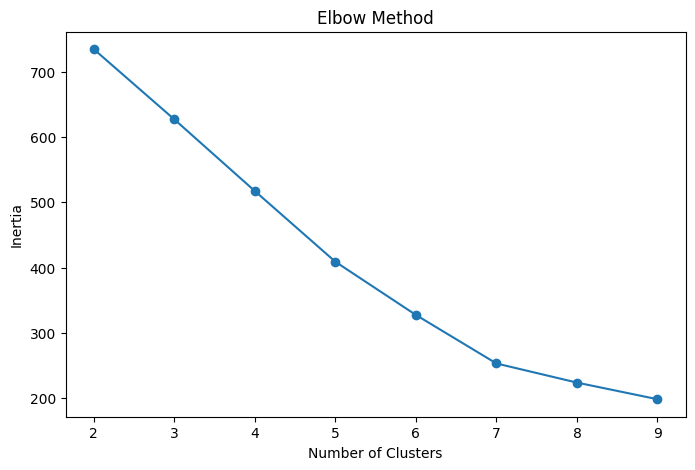

In [32]:
inertia = []
for k in range(2, 10):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)
plt.figure(figsize=(8,5))
plt.plot(
    range(2, 10),
    inertia,
    marker="o"
)
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [33]:
k = 4
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)
df[[
        "Brands",
        "Average_Price",
        "Number of Stores",
        "Countries Available",
        "Sustainability Score",
        "Cluster"]].sort_values("Cluster")

,Brands,Average_Price,Number of Stores,Countries Available,Sustainability Score,Cluster
75,Samaritaine,2550.0,1.0,1.0,2,0
74,Le Bon Marche Rive Gauche,2050.0,1.0,1.0,1,0
0,Barton Perreira,3500.0,460.0,65.0,1,1
1,Berluti,4250.0,290.0,55.0,3,1
4,Fendi,3250.0,200.0,40.0,2,1
...,...,...,...,...,...,...
108,Piaget,19000.0,140.0,50.0,2,3
104,A.Lange & Sohne,55000.0,40.0,30.0,1,3
110,Vancheron Constantin,45000.0,110.0,45.0,1,3
109,Roger Dubuis,115000.0,40.0,30.0,2,3


In [34]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]

In [35]:
fig = px.scatter(
    df,
    x="PCA1",
    y="PCA2",
    color=df["Cluster"].astype(str),
    hover_name="Brands",
    hover_data=[
        "Luxury Tier",
        "Average_Price",
        "Number of Stores",
        "Countries Available",
        "Sustainability Score"
    ],
    title="Luxury Brand Clusters")
fig.show()

In [36]:
cluster_profile = (
    df.groupby("Cluster")[[
            "Average_Price",
            "Price_Ceiling",
            "Number of Stores",
            "Products Offered",
            "Countries Available",
            "Sustainability Score",
            "Founded Age"]]
    .mean()
    .round(2))
cluster_profile

,Average_Price,Price_Ceiling,Number of Stores,Products Offered,Countries Available,Sustainability Score,Founded Age
Cluster,,,,,,,
0,2300.00,175000.00,1.00,275000.00,1.00,1.50,165.00
1,2256.62,384612.05,111.33,1522.51,40.48,1.48,72.26
2,3277.08,264704.17,43.71,505.92,81.75,0.79,221.04
3,41583.33,10325000.00,119.17,2040.83,41.25,1.67,120.25


In [37]:
def compatibility_score(
    row,
    preferred_gender,
    preferred_tier,
    budget,
    sustainability_importance):
    score = 0
    if (row["Target Gender"] == preferred_gender or row["Target Gender"] == "Male & Female"):
        score += 20
    if row["Luxury Tier"] == preferred_tier:
        score += 20
    price = row["Average_Price"]
    if not pd.isna(price):
        difference = abs(price - budget)
        budget_score = max(0,20 - (difference / budget * 20))
        score += budget_score
    sustainability_score = min(row["Sustainability Score"] * 4,20)
    score += (sustainability_score *sustainability_importance)
    score += (row["Global Reach Score"] / 100) * 20
    return min(score, 100)

In [38]:
def recommend_brands(
    data,
    gender,
    tier,
    budget,
    sustainability_importance):
    result = data.copy()
    result["Compatibility Score"] = result.apply(
        lambda row: compatibility_score(
            row,
            gender,
            tier,
            budget,
            sustainability_importance),axis=1)
    return result[[
            "Brands",
            "Luxury Tier",
            "Average_Price",
            "Sustainability Score",
            "Global Reach Score",
            "Compatibility Score"
        ]].sort_values("Compatibility Score",ascending=False)

In [39]:
recommendations = recommend_brands(
    df,
    gender="Male & Female",
    tier="Ultra Luxury",
    budget=50000,
    sustainability_importance=1)
recommendations.head(10)

,Brands,Luxury Tier,Average_Price,Sustainability Score,Global Reach Score,Compatibility Score
65,Hublot,Ultra Luxury,22500.0,4,43.750,73.750
60,Bvlgari,Ultra Luxury,9000.0,3,43.750,64.350
88,Gucci,Ultra Luxury,3000.0,2,62.500,61.700
101,Cartier,Ultra Luxury,9000.0,2,43.750,60.350
89,Saint Laurent,Ultra Luxury,2750.0,1,50.000,55.100
59,Parfums Christian Dior,Ultra Luxury,165.0,0,75.000,55.066
3,Christian Dior Couture,Ultra Luxury,3150.0,2,28.125,54.885
90,Bottega Veneta,Ultra Luxury,3500.0,1,46.875,54.775
4,Fendi,Ultra Luxury,3250.0,2,25.000,54.300
20,Armand De Brignac,Ultra Luxury,525.0,1,50.000,54.210


In [40]:
def compare_brands(data, brand1, brand2):
    cols = [
        "Brands",
        "Luxury Tier",
        "Production",
        "Average_Price",
        "Price_Ceiling",
        "Number of Stores",
        "Products Offered",
        "Countries Available",
        "Sustainability Score",
        "Founded Age"]
    return data[data["Brands"].isin([brand1, brand2])][cols]

In [41]:
compare_brands(
    df,
    df["Brands"].iloc[0],
    df["Brands"].iloc[1]
)

,Brands,Luxury Tier,Production,Average_Price,Price_Ceiling,Number of Stores,Products Offered,Countries Available,Sustainability Score,Founded Age
0,Barton Perreira,Premium Luxury,Fashion & Leather Goods,3500.0,1000000.0,460.0,4500.0,65.0,1,19.0
1,Berluti,Haute Luxury,Fashion & Leather Goods,4250.0,500000.0,290.0,3500.0,55.0,3,131.0


In [42]:
def radar_comparison(data, brand1, brand2):
    metrics = [
        "Global Reach Score",
        "Sustainability Initiatives",
        "Number of Stores",
        "Products Offered",
        "Founded Age",
        "Average_Price"]
    labels = [
        "Global Reach",
        "Sustainability",
        "Stores",
        "Products",
        "Heritage",
        "Price"]
    b1 = data[data["Brands"] == brand1].iloc[0]
    b2 = data[data["Brands"] == brand2].iloc[0]
    values1 = [b1[m] for m in metrics]
    values2 = [b2[m] for m in metrics]
    fig = go.Figure()
    fig.add_trace(go.Scatterpolar(r=values1,theta=labels,fill="toself",name=brand1))
    fig.add_trace(go.Scatterpolar(r=values2,theta=labels,fill="toself",name=brand2))
    fig.update_layout(polar=dict(radialaxis=dict(visible=True,range=[0, 1])),title=f"{brand1} vs {brand2}")
    fig.show()

In [43]:
brands = df["Brands"].tolist()
radar_comparison(
    df,
    brands[3],
    brands[4])

In [44]:
production = (
    df["Production"]
    .value_counts()
    .reset_index())
production.columns = [
    "Production Category",
    "Number of Brands"]
fig = px.bar(
    production,
    x="Number of Brands",
    y="Production Category",
    orientation="h",
    title="Luxury Brands by Production Category")
fig.show()

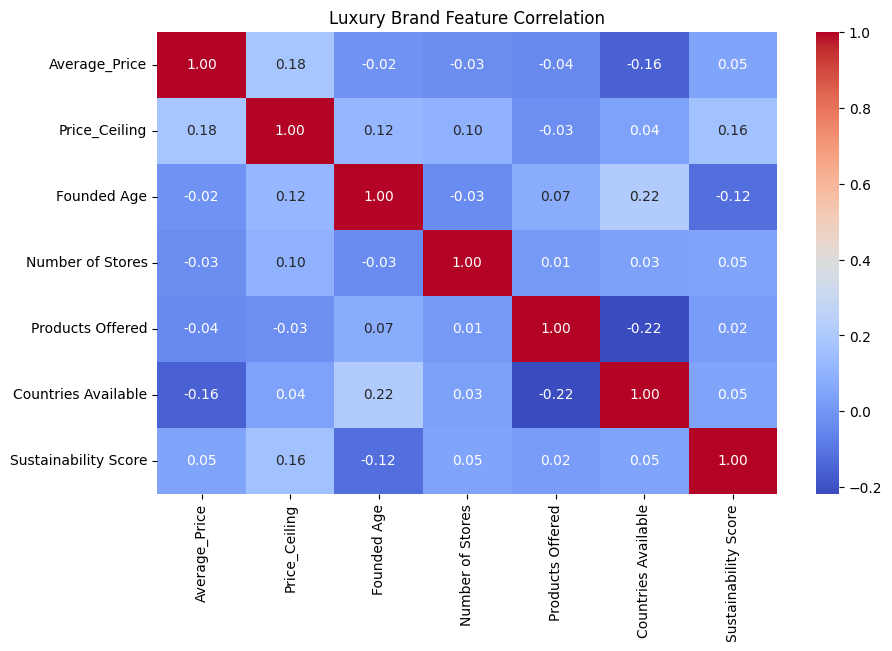

In [45]:
correlation_features = [
    "Average_Price",
    "Price_Ceiling",
    "Founded Age",
    "Number of Stores",
    "Products Offered",
    "Countries Available",
    "Sustainability Score"]
corr = df[correlation_features].corr()
plt.figure(figsize=(10,6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f")
plt.title("Luxury Brand Feature Correlation")
plt.show()

In [46]:
corr_pairs = (corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().sort_values(ascending=False))
corr_pairs

Founded Age          Countries Available     0.215611
Average_Price        Price_Ceiling           0.180241
Price_Ceiling        Sustainability Score    0.162755
                     Founded Age             0.116048
                     Number of Stores        0.096101
Founded Age          Products Offered        0.073612
Countries Available  Sustainability Score    0.049239
Average_Price        Sustainability Score    0.048378
Number of Stores     Sustainability Score    0.045796
Price_Ceiling        Countries Available     0.039064
Number of Stores     Countries Available     0.032567
Products Offered     Sustainability Score    0.020477
Number of Stores     Products Offered        0.009506
Average_Price        Founded Age            -0.015584
Price_Ceiling        Products Offered       -0.025198
Average_Price        Number of Stores       -0.027287
Founded Age          Number of Stores       -0.034310
Average_Price        Products Offered       -0.037430
Founded Age          Sustainability Score   -0.119513
Average_Price        Countries Available    -0.156155
Products Offered     Countries Available    -0.216916
dtype: float64

In [47]:
df.shape

(123, 33)

In [48]:
df.to_excel("Luxury_Brand_Analysis.xlsx",index=False)
print("Saved successfully!")

Saved successfully!


In [49]:
from google.colab import files
files.download("Luxury_Brand_Analysis.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>